SOMs
- don't use numbers e.g. 2 dimensions, 3 clusters.
- cite classical reference for self-organising maps
- talk about variations on the neural network. refer to paper that uses som's to do feature selection.
- convergence analysis on self-organising maps with starting points, number of signals. see which are the best features in each case.
- decide whether to use SOMs

write-up notes
- don't start (conclusion not summary) with overall
- american english
- use a consistent tense (usually past)
- use commands
- use feature names instead of cluster number
- look at kurtosis to separate measurement noise from broadband
- use (j, k) notation.
- write about standardisation in manuscript
- discuss k-means parameters

- only cluster nodes up to a meaningful frequency
- implement fft function
- discuss k-means parameters

- read + write about k-means
- do numerical experiments
- add new details about the method (maximum frequency, minimum entropy, "lloyd")

plotting
- use scatter and bar charts of k-means & the FFT overlap
- include tree diagram for a smaller decomposition
- save figures as ps or pdf
- make labels larger, make sure units are right

writing!
- tested coiflets. they are more compact but still consistent with the results from daubechies
- signal to noise based on power instead of mean
- implemented variable number of cycles
- use scipy.signal.blackmanharris(sym=False)
- take off mean, window, standardise

SOMs
- implement parallel processing in generate_training_data_with_wavelet
- simplify the SOMs code, use constant std_noise

- report numerical analysis results
- include results for all 4 cases
- use log scale for average energy
- plot all datasets together
- min level to 5
- c1, c5, 10
- save results
- manually label clusters
- do the same for the ga data
- compare minimum level of decomposition set to 3, 7.
- test mixture of gaussians?

- implement preprocess function in utils.preprocessing across relevant notebooks
- ga data plots with standard deviation bar
- write up everything except results.
- change notation of average energy

Reza
- decovolution
- gilmore simulations, at th efrequency and amplitudes of pcd data
- double check implementation of gilmore, write down a set of parameters to test algorithm on
- collect experimental data 3 times per protocol.


# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

import numpy as np
import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.extensions import fft
from wavelet_transform.utils.machine_learning import fit_and_evaluate, train_k_means, assess_parameter
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.preprocessing import preprocess

### Parameters

Specify parameters for synthetic data and wavelet transform

pac = -20e5
frequency = 1E6             # insonation frequency (Hz)  
fs = 1E9              # sampling rate to generate the time vector  
tstep = 1./fs  
R_init = 1E-6                  # initial bubble radius in meters  
Rdot_init = 0                   # initial bubble's wall velocity in m/s  
r_measure = 500*R_init        

### stable
R_init = -0.1E6                     # the amplitude of the sine wave in Pa  

### transient
pac = -1E6                     # the amplitude of the sine wave in Pa  

pac = 100 kPa, 1 MPa, 2 MPa, 4 MPa
frequency = 1MHz
R_init = 1e-6, 10e-6

In [3]:
# Set sampling rate and noise std
sampling_rate = 50e6
signal2noise = 30

# Bubble dynamcis parameters
R_init = 100e-6
frequency = 1e6
pac = -20e5

# Parameters for FFT plot
fft_lim = 5

# Parameters for the wavelet transform
wavelet = "db10"
levels = None  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 3
freq_threshold = 20e6  / (sampling_rate / 2)  # the nodes with norm_freq_range above this threshold will not be kept

### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [4]:
# BUBBLE DYNAMICS DATA
data, t_plot = train.get_data(R_init, frequency, pac, sampling_rate, return_time=True, n_cycles=100)

# Add noise
mean_std_noise_ratio = 10 ** (signal2noise / 20)
std_noise = abs(np.average(data)) / mean_std_noise_ratio
noise = np.random.normal(0, std_noise, len(data))
data += noise
print("std noise:", std_noise)

std noise: 0.03151507216097667


In [5]:
# Normalise
data_processed = preprocess(data, window=False)

In [6]:
# Plot generated data
fft_data, freq = fft(data, sampling_rate, frequency)
# plot sound wave and fft
fig = make_subplots(rows=3, cols=1)
fig.add_trace( go.Scatter(x=t_plot, y=data_processed, mode='lines',name='data'),
              row=1,col=1)
fig.add_trace( go.Scatter(x=freq,y=np.log10(np.abs(fft_data)),mode='lines',name='fft - amp'),
              row=2,col=1)
fig.add_trace( go.Scatter(x=freq, y=np.angle(fft_data, deg=True),mode='lines', name = 'fft - phase'),
              row=3,col=1)

fig.update_layout(height=600, width=800,
                  xaxis1 = dict(title='Time [s]'),
                  xaxis2 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  xaxis3 = dict(title='Freq [f/f_0]', range=[0, fft_lim]),
                  yaxis1 = dict(title='Amplitude [DL]'),
                  yaxis2 = dict(title='Amplitude [dB]'),
                  yaxis3 = dict(title='Amplitude [rad]'))
fig.show()

Wavelet transform

In [7]:
wpt_df, tr_obj = train.generate_training_data(
    data_processed, levels, wavelet, mode, 
    include_tr_obj=True, min_entropy=use_min_entropy,
    min_level=min_level, freq_threshold=freq_threshold
)

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [8]:
# tr_obj.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_obj, max(t_plot))

In [9]:
# wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

### K-means without PCA

In [10]:
# k-means parameters
kmeans_params = {"init": "k-means++",
    "n_init":10,
    "max_iter":100,
    "tol":1e-8,
    "verbose":0,
    "algorithm":"lloyd",
    }

# training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    # "crest factor",
    # "log average energy",
    # "level entropy",
    "spectral entropy",
    # "skewness"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
use_inverse_metrics = False
if use_inverse_metrics is True:
    inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object instead
    wpt_df_train = inv_tr_obj.info(leaf_nodes=True)
else:
    wpt_df_train = wpt_df.copy()

In [11]:
data_train, labels, data_train_normalised, centers, _, kmeans = train_k_means(
    wpt_df_train, classifying_metrics, no_clusters=no_clusters, kmeans_params=kmeans_params
)

### Evaluate k-means using a range of metrics 

see scikit learn documentation https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html

In [12]:
# fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data', n_runs=100)

Numerical sensitivity analysis

In [13]:
# parameter_of_interest = "max_iter"
# values = [i for i in range(1, 100, 2)]
# rand_indices = assess_parameter(
#     parameter_of_interest, values, wpt_df_train, 
#     classifying_metrics, no_clusters
# )

# plt.plot(values, rand_indices)
# plt.title(f"Effect of {parameter_of_interest} on clustering algorithm")
# plt.ylabel("Adjusted rand index")
# plt.xlabel(f"{parameter_of_interest.capitalize()}")
# plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [14]:
# data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
#     wpt_df_train, classifying_metrics, no_clusters=no_clusters, use_pca=True, kmeans_params=kmeans_params
# )

## Save results

In [15]:
result_id = f"{R_init}_{frequency}_{pac}"
results.save_data(result_id, data_train, tr_obj, centers, labels, sampling_rate, freq_threshold)

# Plotting

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

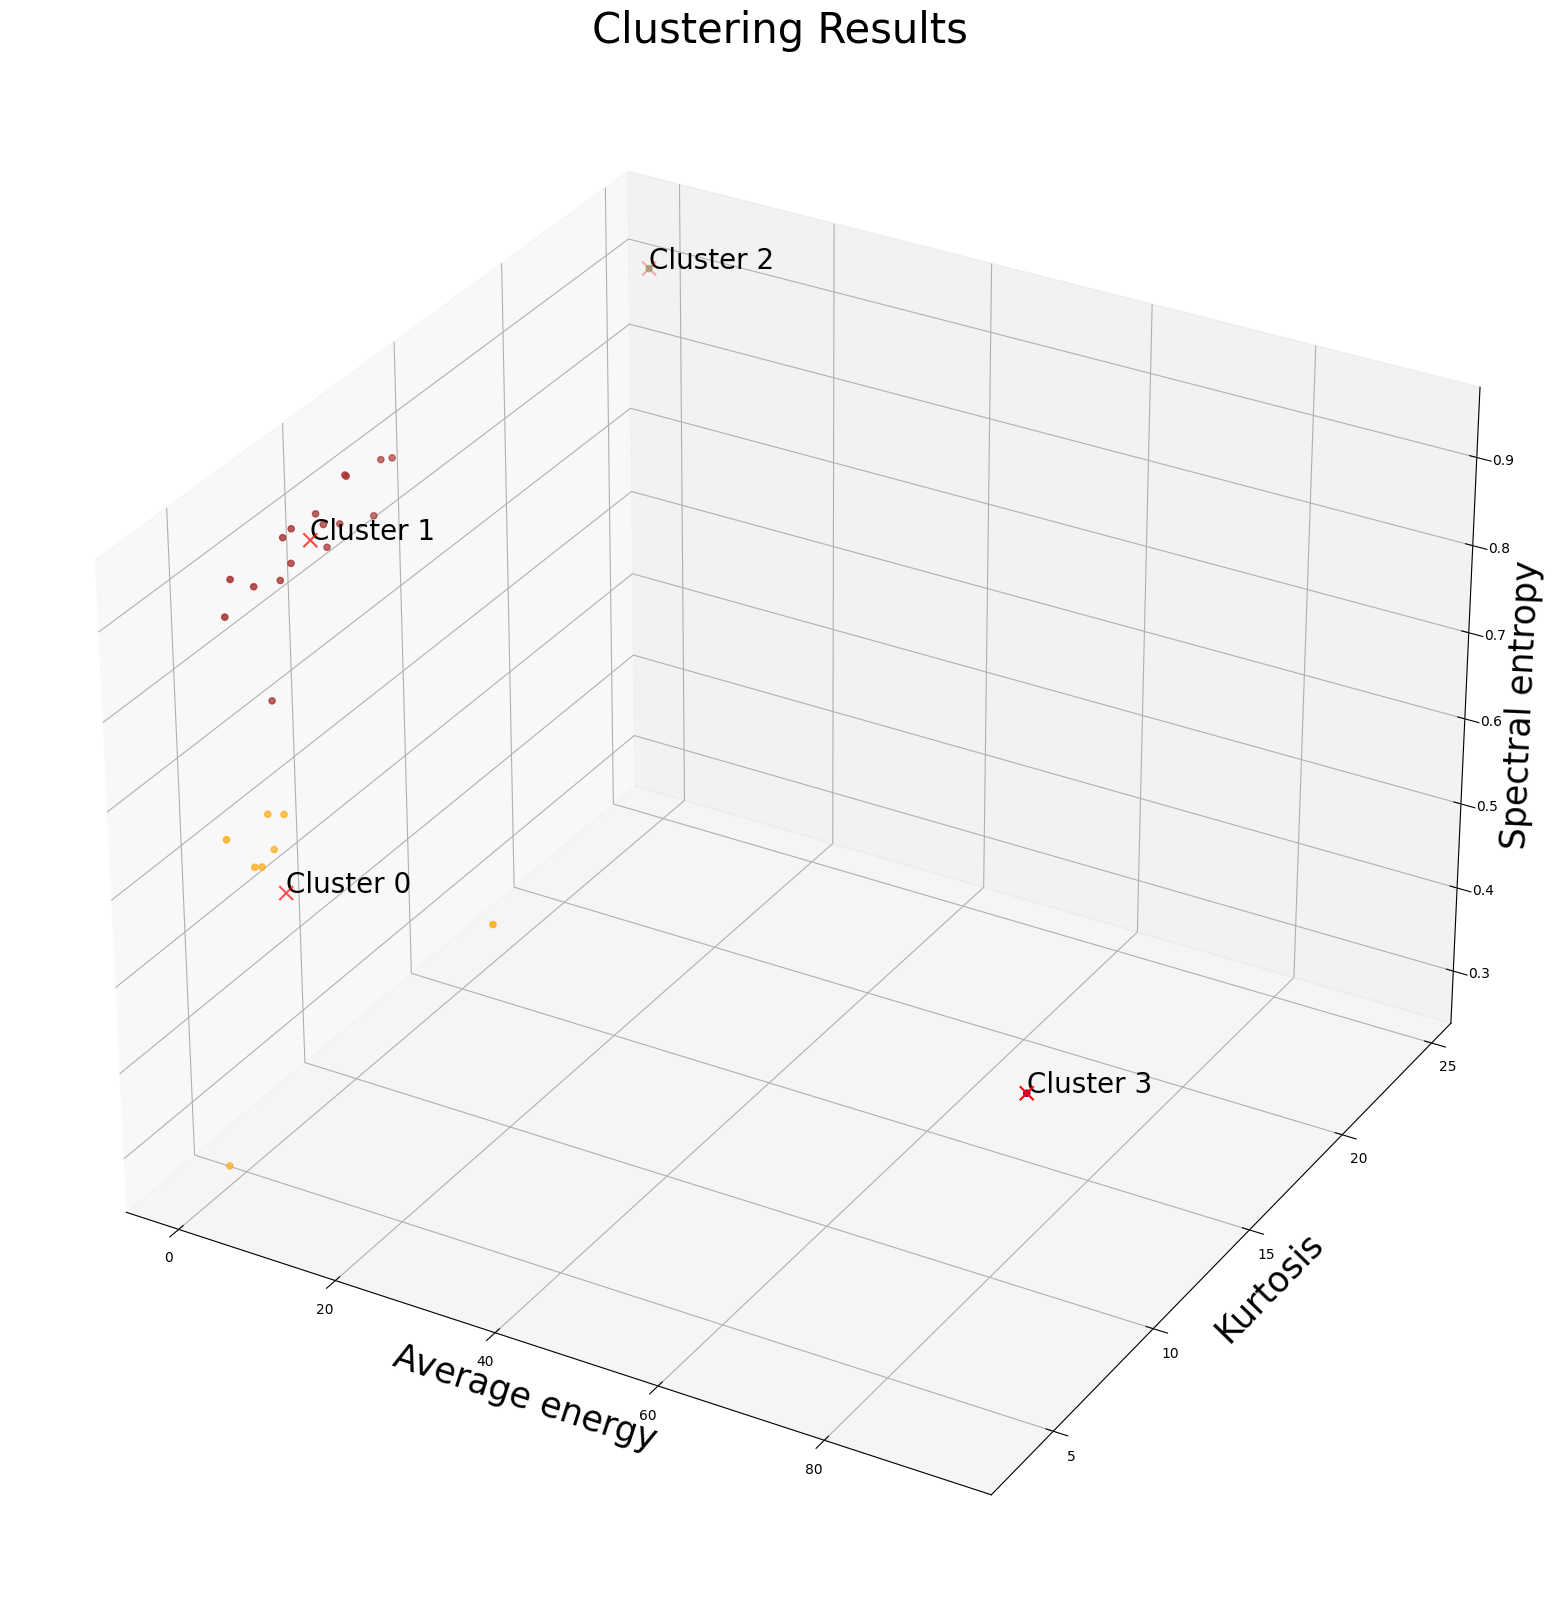

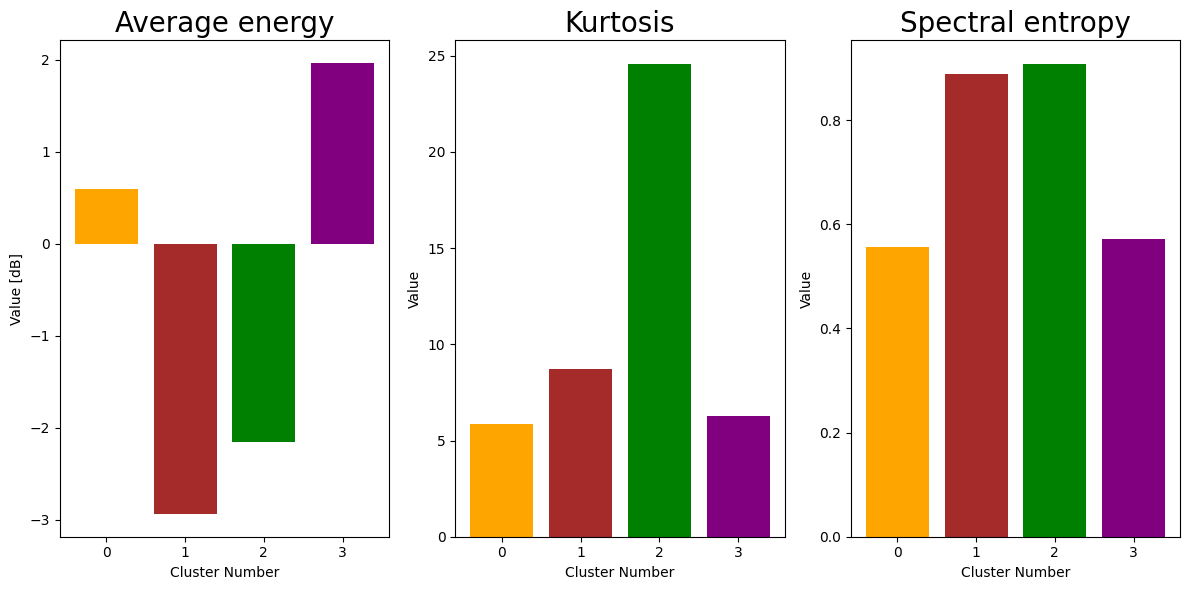

In [16]:
fig = plot.plot_clustering(data_train, centers, labels)

# Plot centroid metrics
fig = plot.plot_centers(classifying_metrics, centers)

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

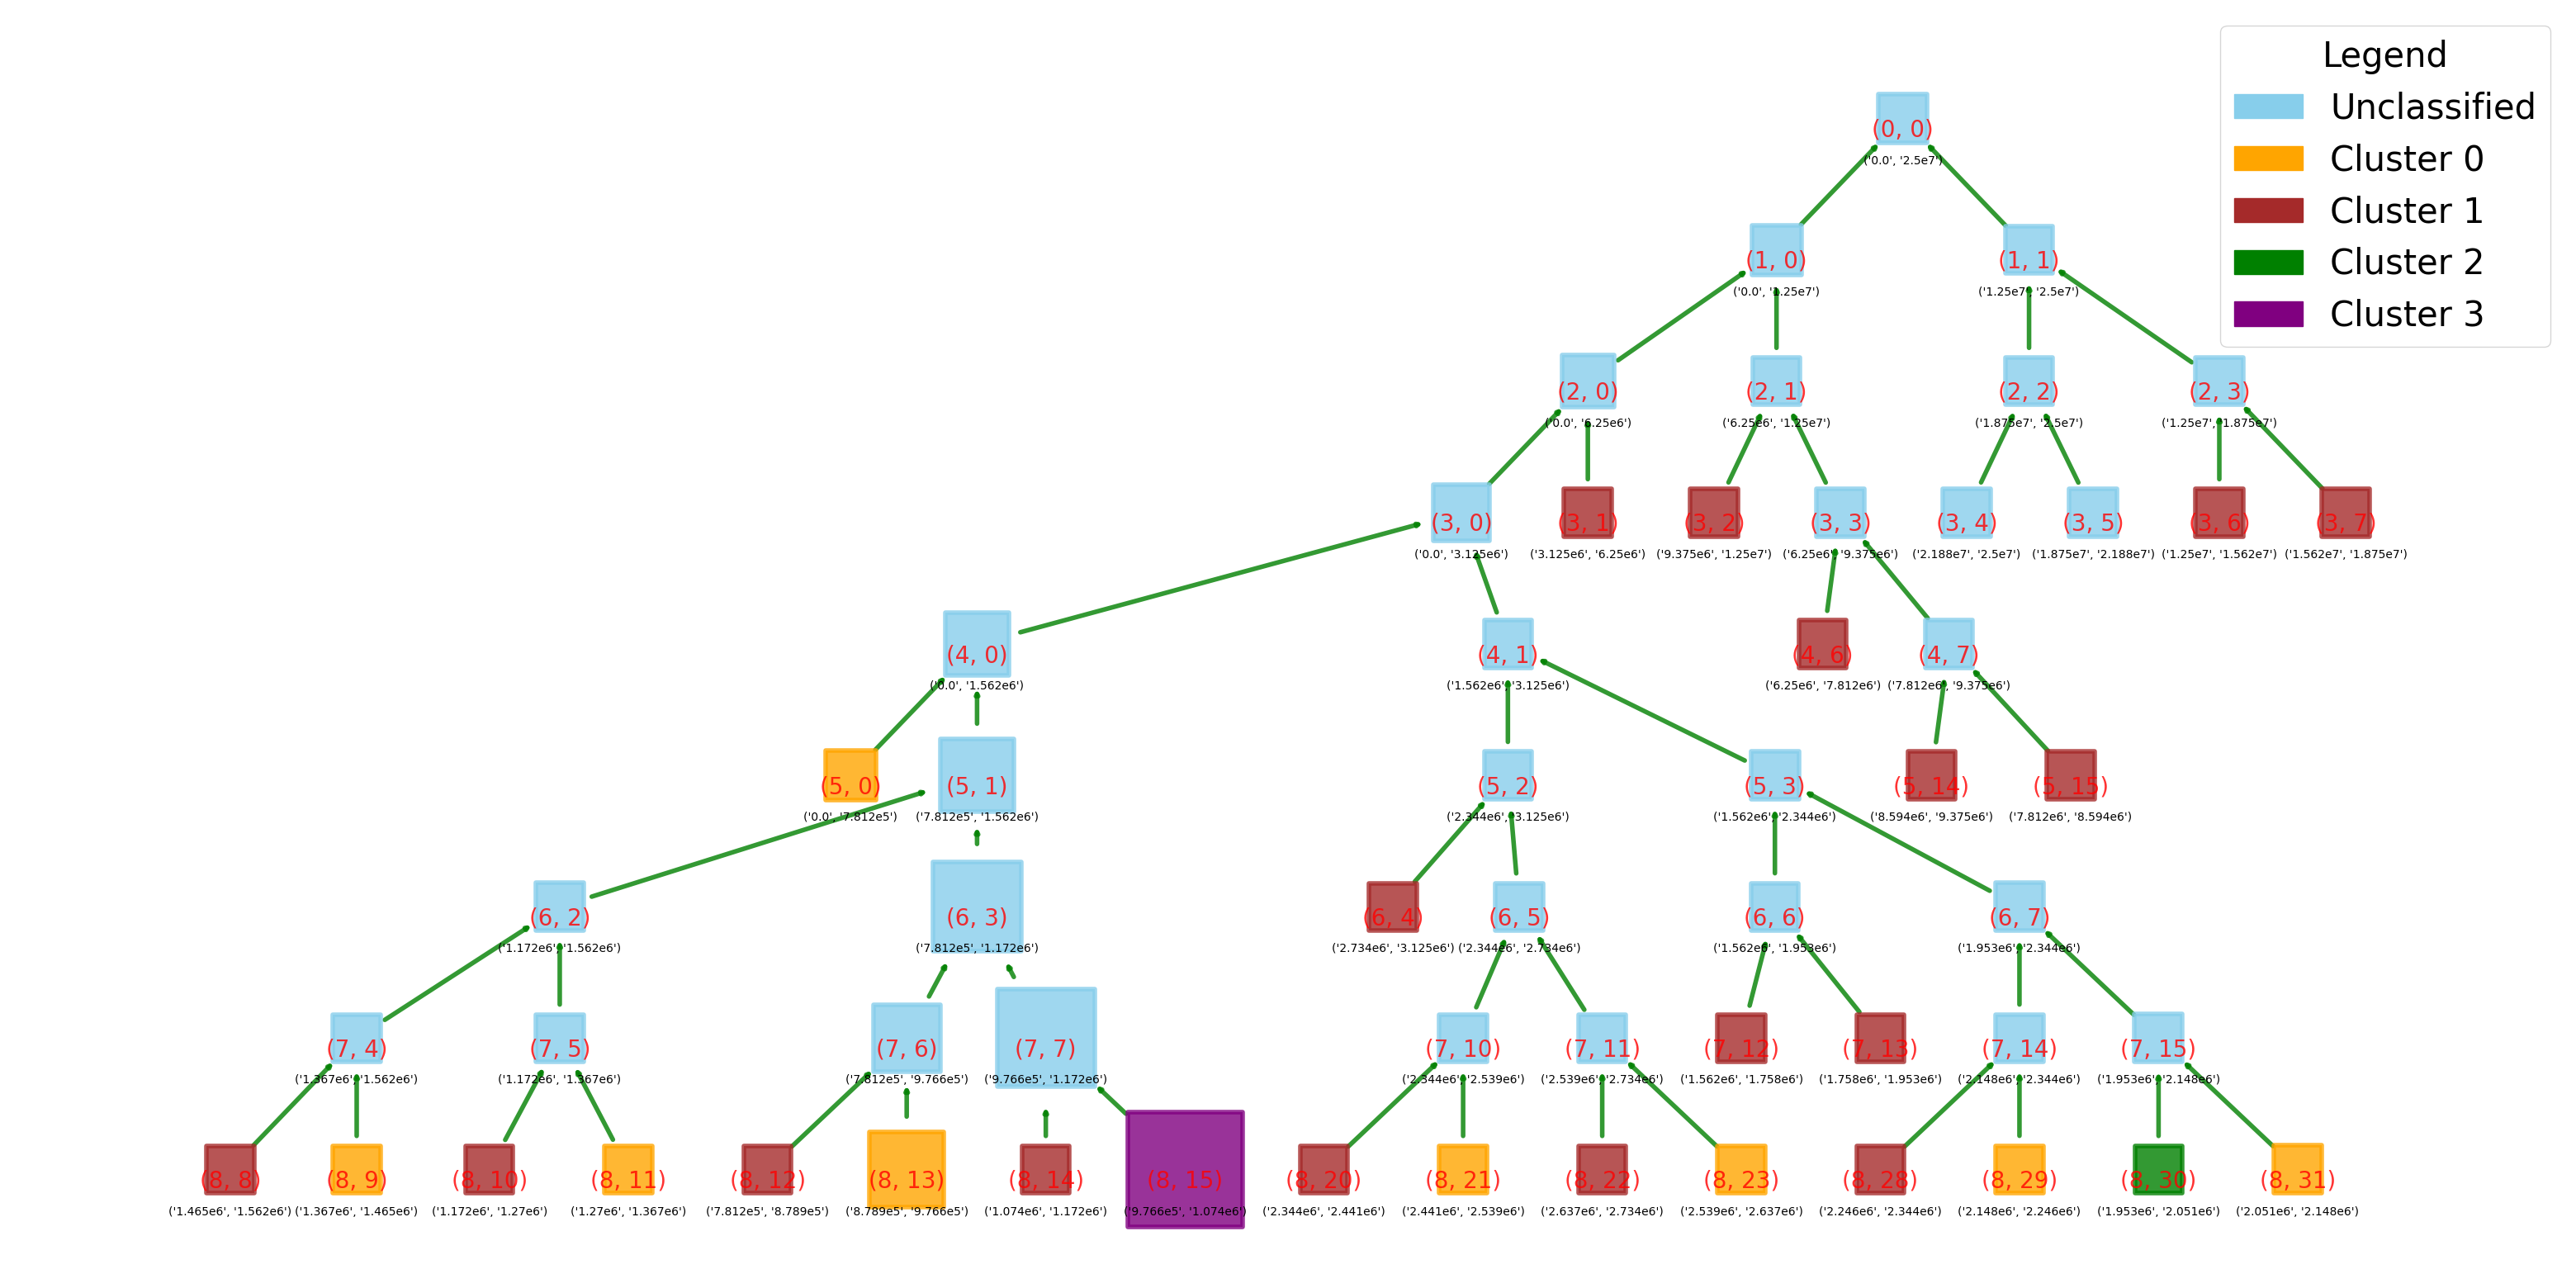

In [17]:
tr_obj.calc_frequencies(sampling_rate)
tr_obj.plot_tree(node_size="average energy", node_colour=list(labels), freq_threshold=freq_threshold)

In [18]:
# Set clusters to None to plot all of them, otherwise, plot a list of int
fig = plot.plot_fft_by_group(
    tr_obj, labels, no_clusters, sampling_rate,
    clusters=None, xlim=10, fundamental_freq=frequency,
    freq_threshold=freq_threshold
)

fig = plot.plot_reconstructions_by_group(tr_obj, labels, no_clusters, t_plot, freq_threshold)

pca results

In [19]:
# plot pca results
# plot.plot_reconstructions_by_group(tr_obj, labels_pca, no_clusters, t_plot, sampling_rate)

separately plot reconstructions of all nodes belonging to selected clusters

spectral entropy: 0.8823596130741717


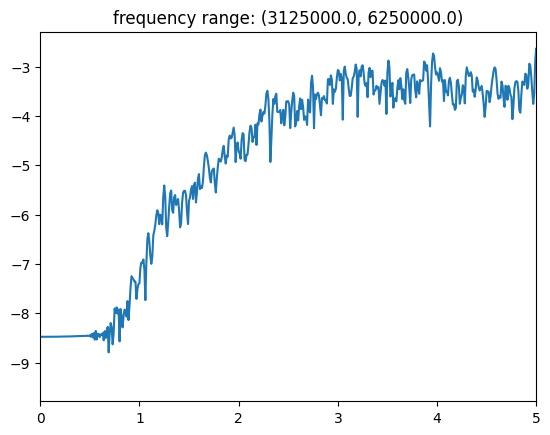

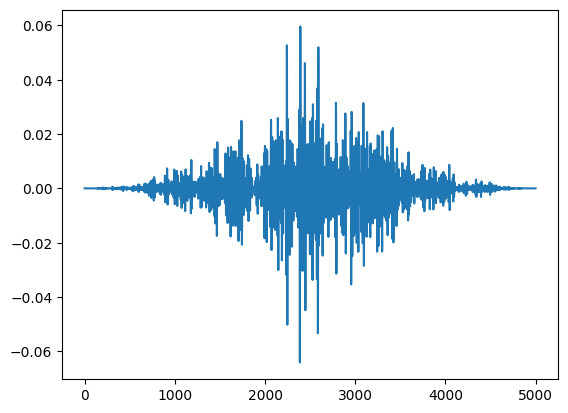

spectral entropy: 0.9316042350495992


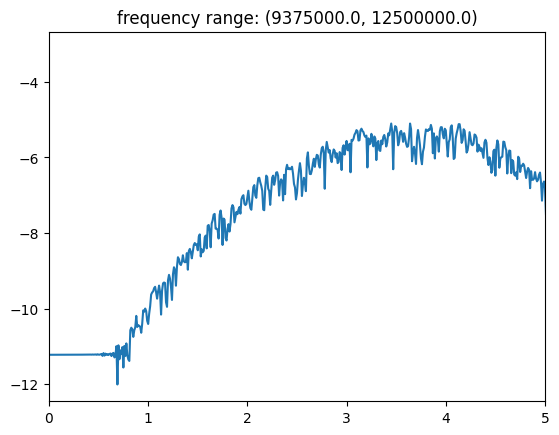

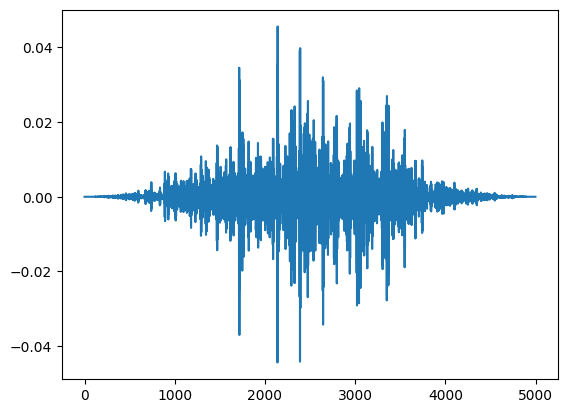

spectral entropy: 0.9291348486584675


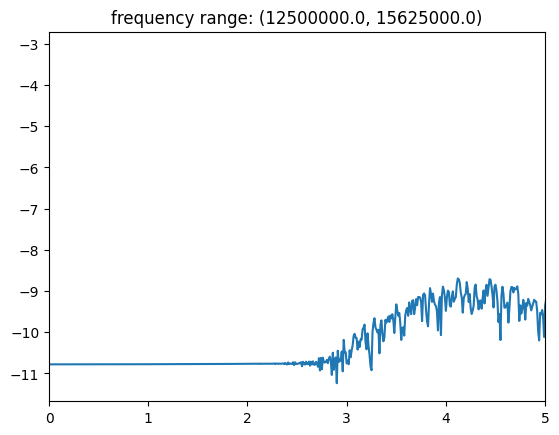

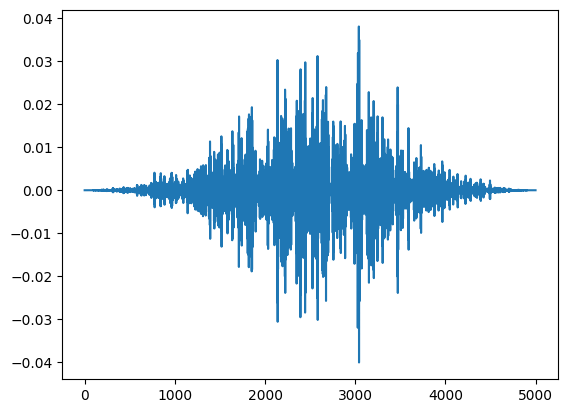

spectral entropy: 0.9189561800102062


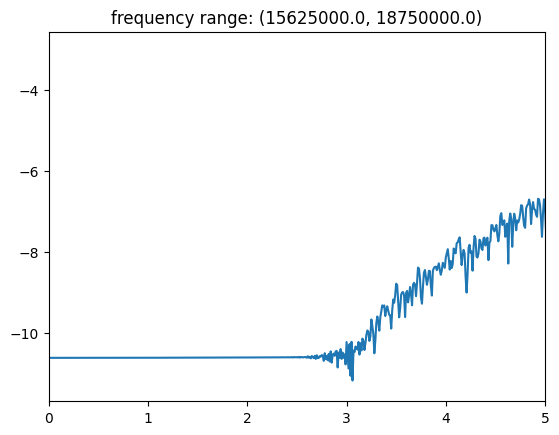

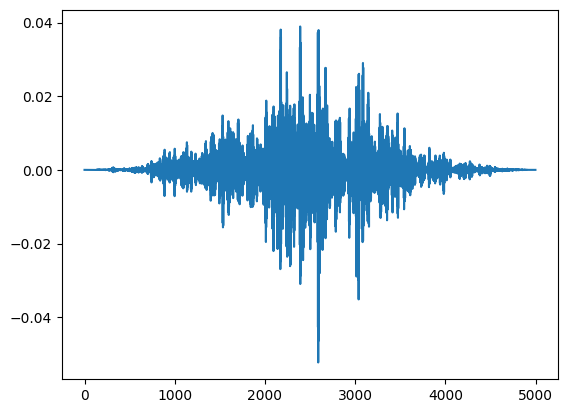

spectral entropy: 0.9140309934086072


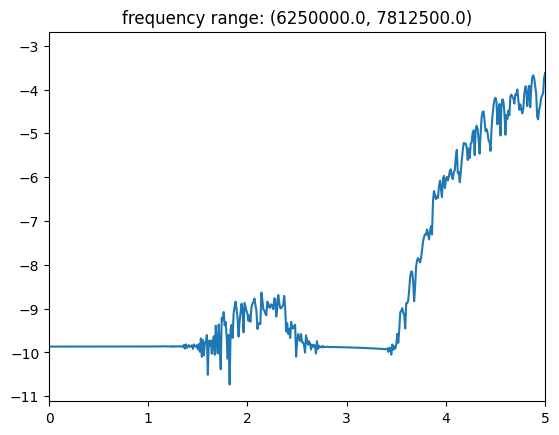

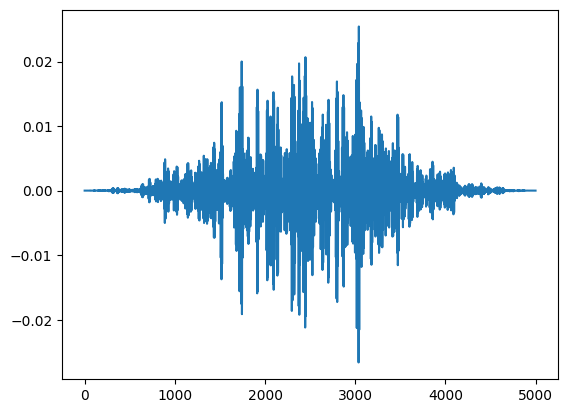

spectral entropy: 0.8844461195143593


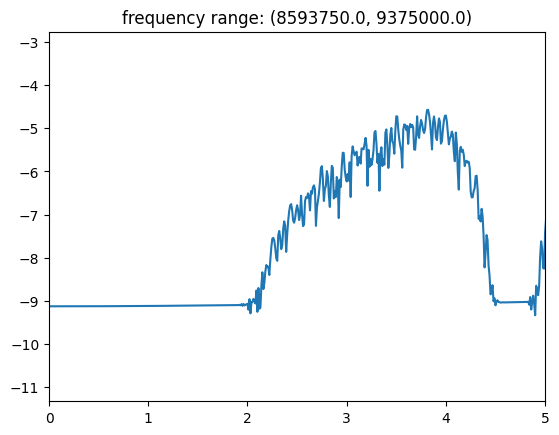

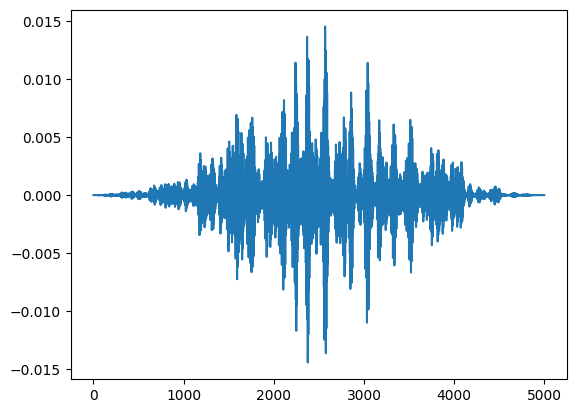

spectral entropy: 0.8672185130870053


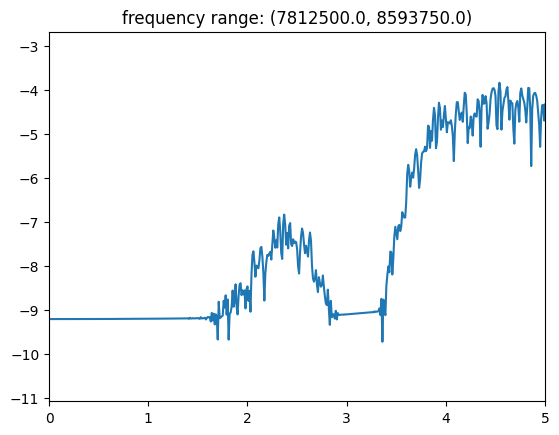

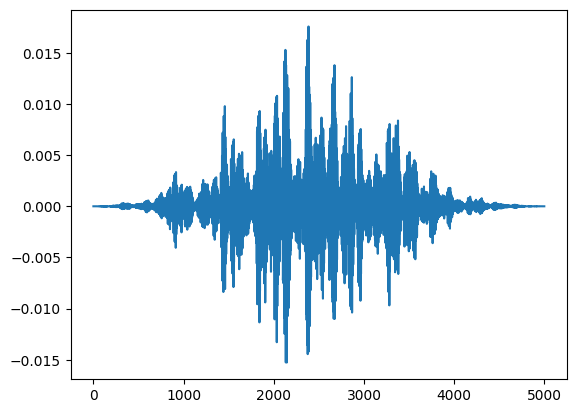

spectral entropy: 0.8695909729365849


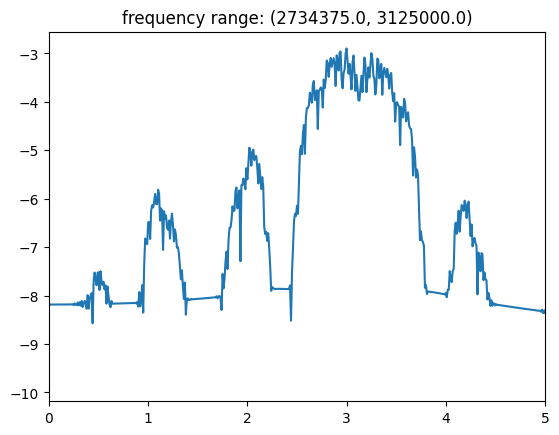

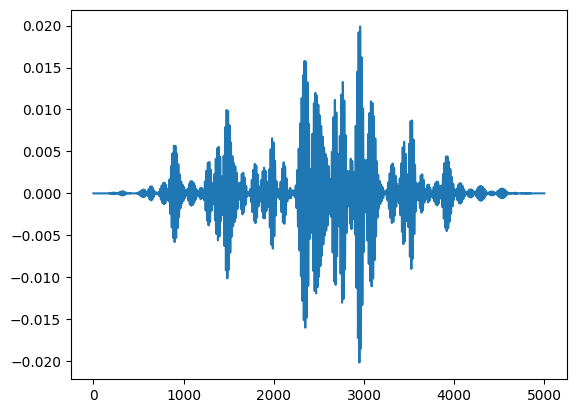

spectral entropy: 0.9167220487006522


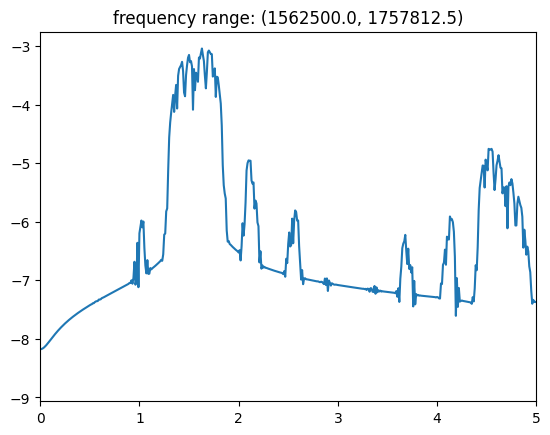

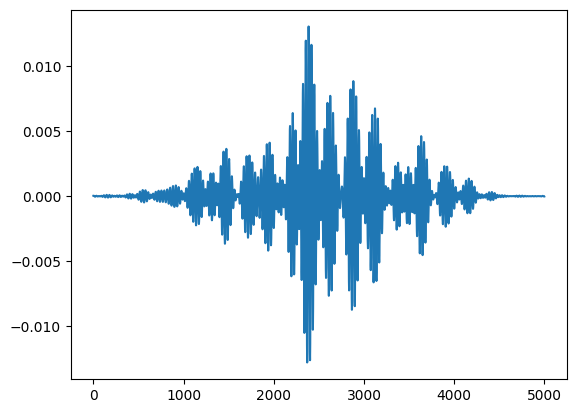

spectral entropy: 0.8630208187492223


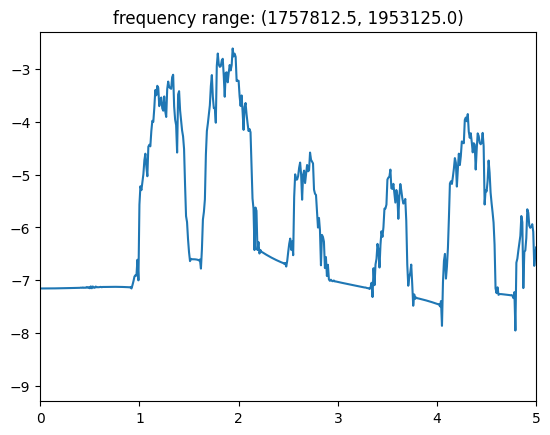

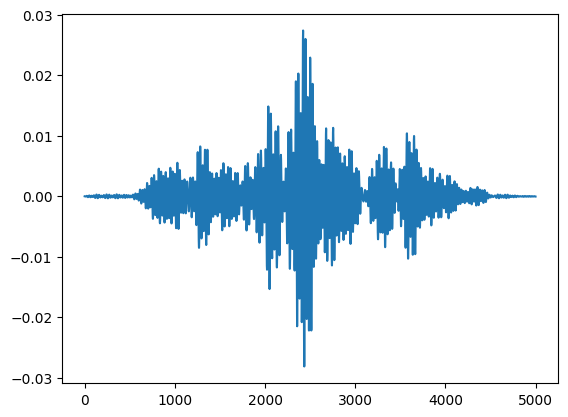

spectral entropy: 0.9113927498318865


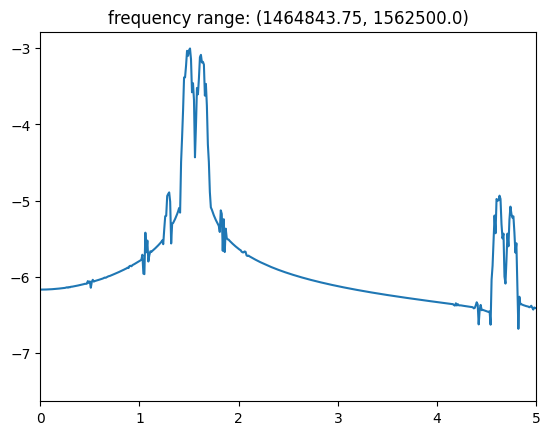

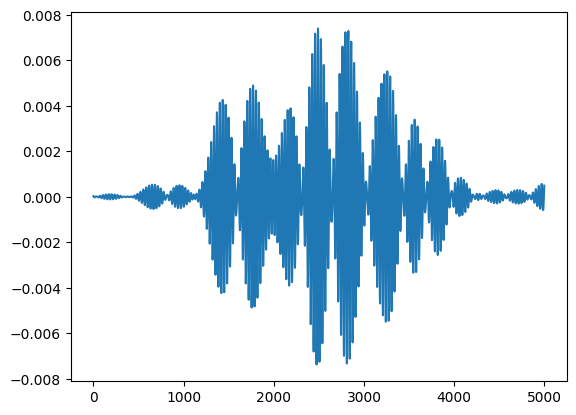

spectral entropy: 0.8951739686144919


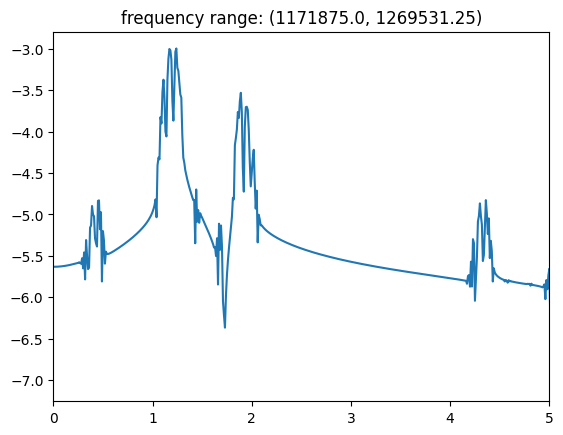

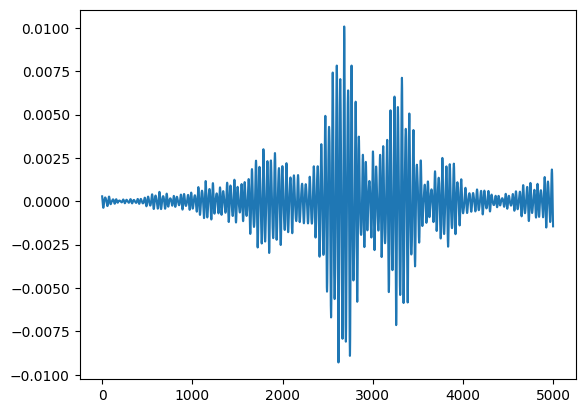

spectral entropy: 0.9131315613837038


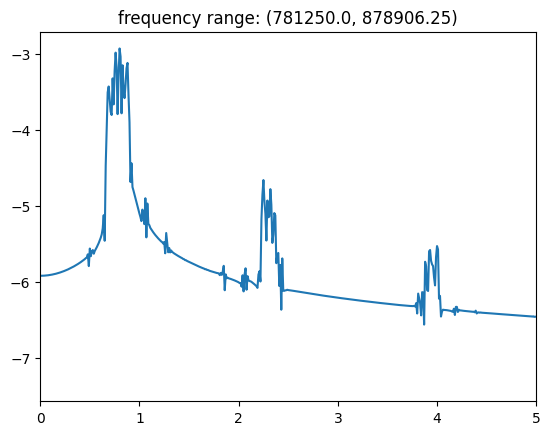

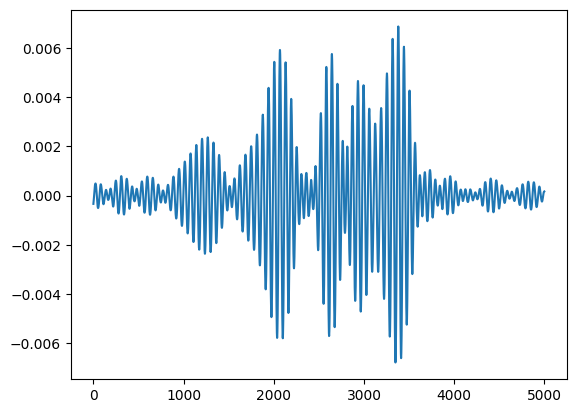

spectral entropy: 0.7448925510387352


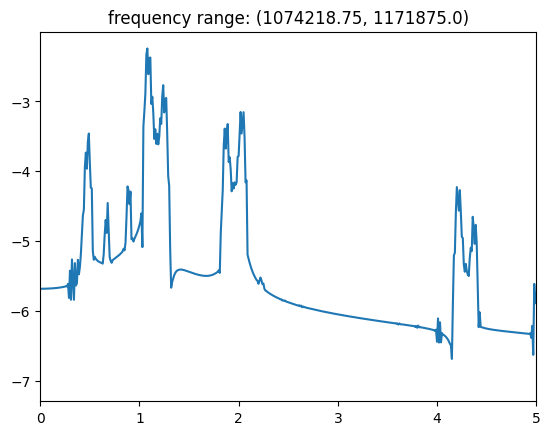

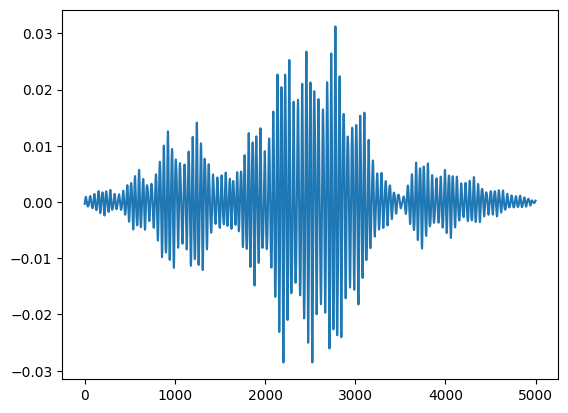

spectral entropy: 0.9115561238492909


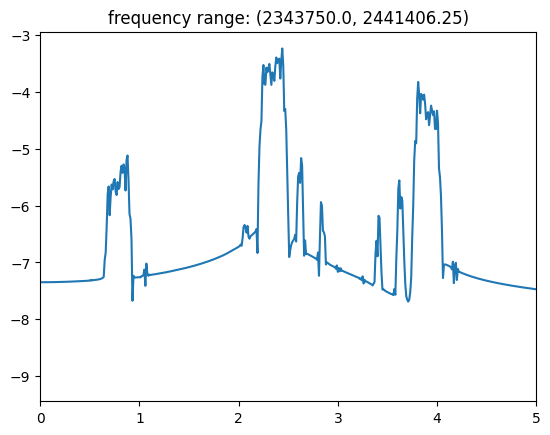

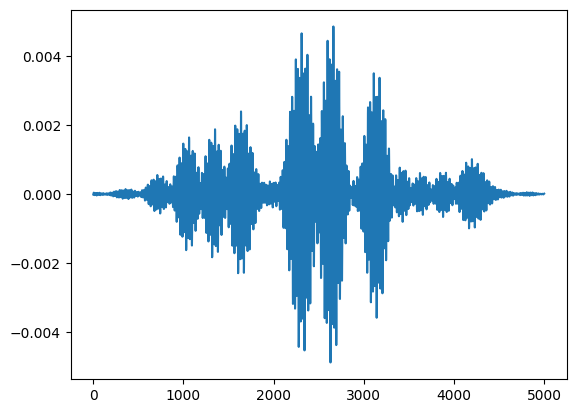

spectral entropy: 0.879376769457274


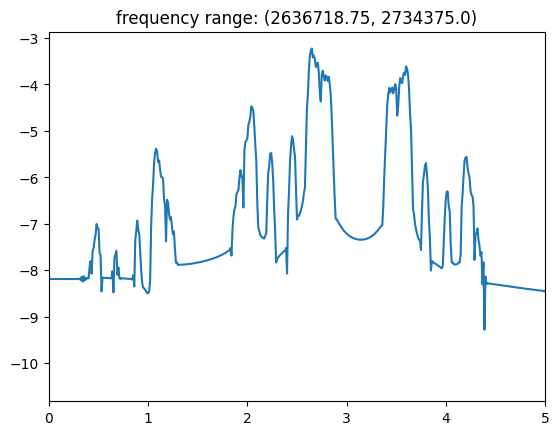

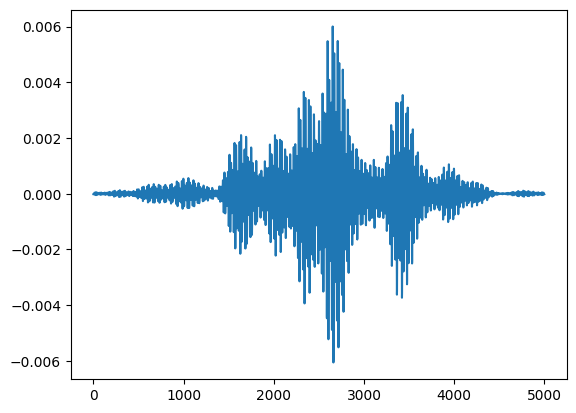

spectral entropy: 0.8752031392890443


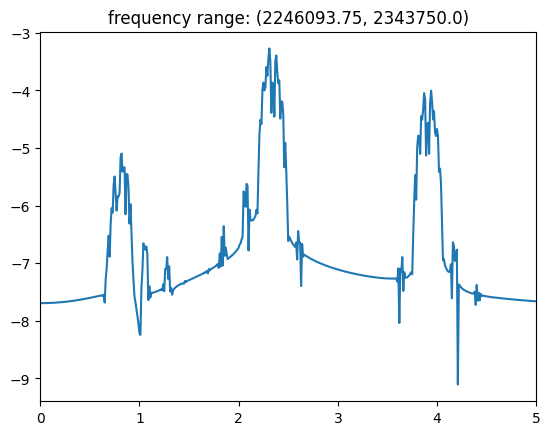

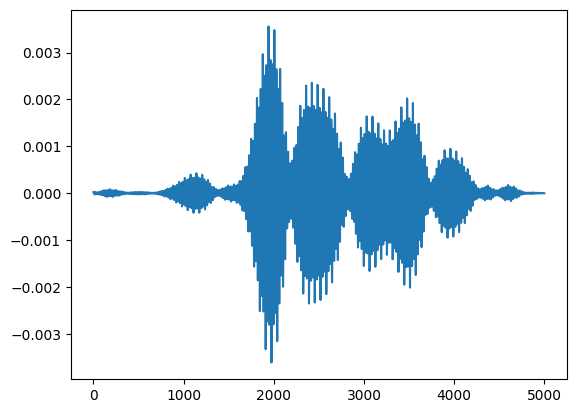

In [20]:
import wavelet_transform.wpt.inverse_transform as inv
# Add number to list to plot reconstructions of all nodes belonging to the cluster

plot_centres = [1]
for i, (node, assignment) in enumerate(zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), labels)):
    freq /= frequency
    if assignment in plot_centres:
        print("spectral entropy:", node.spectral_entropy)
        rec = inv.inv_dwpt(tr_obj, node.level, nodes=node)
        fft_rec, freq = fft(rec, sampling_rate, frequency)
        plt.plot(freq, np.log10(np.abs(fft_rec)))
        plt.xlim(0, 5)
        plt.title(f"frequency range: {node.frequency_range}")
        plt.show()
        plt.plot(rec)
        plt.show()
